# P10 — Programas gênicos por NMF (Yasumizu et al., 2024) como alternativa ao Leiden

**O método do artigo.** Yasumizu et al. (2024, *Cell Genomics* 4:100473)
montaram um atlas de 1,8 milhão de células T CD4⁺ do sangue. Os 18 tipos de
referência do atlas foram definidos com Leiden. Para descrever a variação
dessas células, porém, os autores propõem outra coisa: como o CD4⁺ é um
contínuo, "delimitar artificialmente" clusters não serve, e cada célula vira
uma **combinação de programas gênicos** obtidos por fatoração não negativa
(NMF). No atlas, foram 12 programas: Naive-F, Treg-F, Th17-F, Cytotoxic-F, IFN-F
etc.

**A receita**, do tutorial e dos Métodos dos autores (repositório
NMFprojection):

1. lognorm e genes variáveis;
2. regressão de UMIs, %MT e ciclo celular; escala (corte em 10);
3. negativos → 0;
4. `sklearn` NMF (`init="random"`);
5. número de programas: depois do cotovelo da variância explicada e antes de a
   correlação máxima entre componentes subir.

**Aqui:**

* a entrada do passo 2 é a matriz **corrigida pelo ComBat** (a integração
  escolhida no P07), nas 2.000 HVG do P05;
* para comparar com o Leiden (P11), o "cluster" de cada célula é o **programa
  dominante**: o de maior contribuição, com os programas normalizados para o
  mesmo peso total;
* além da NMF de novo, as células são **projetadas nos 12 programas
  publicados** (NMFproj: W fixa, só H é estimada, sobre a lognorm sem escala),
  o uso que os autores fazem em dados novos.

A computação (57 ajustes, estabilidade, projeção) roda antes, em
`raw/run_nmf.py`, com cache em `HEAVY_OUT/P10_nmf/`. Este notebook só lê o cache.

Limite de inferência: 7 pacientes, 14 bibliotecas.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import json
import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy import stats
from sklearn.metrics import adjusted_rand_score

from functions import anotacao as an, atlas, config, fmt as F, io, nmf, plotting
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)

NB = "P10_nmf_programas"
log = IssueLog(NB)
INK = plotting.INK
CAT = plotting.CATEGORICAL

In [2]:
main = ad.read_h5ad(io.data_path("P05_integracao", "reseq_raw_integrado", "h5ad"), backed="r")
integ = ad.read_h5ad(io.data_path("P07_benchmark_integracao", "integracao_escolhida", "h5ad"))
keys = main.obs["cell_key"].astype(str).to_numpy()
anot = pd.read_parquet(io.data_path("P09_anotacao", "anotacao", "parquet")).set_index("cell_key").reindex(keys)
genes = pd.read_parquet(nmf.CACHE / "entradas" / "genes.parquet")["gene"].to_numpy()
meta_in = json.loads((nmf.CACHE / "entradas" / "assinatura.json").read_text())
N = len(keys)
lib = main.obs["library_id"].astype(str).to_numpy()
print(f"{F.n(N)} células × {F.n(len(genes))} genes na entrada da NMF; {F.pct(meta_in['fracao_zeros'], 0)} de zeros "
      f"(negativos zerados, como na receita)")

35.247 células × 2.000 genes na entrada da NMF; 87% de zeros (negativos zerados, como na receita)


## 1. Quantos programas

Para k = 2…20, três sementes cada: a variância explicada, a correlação
máxima entre dois programas (pesos dos genes; Spearman, como no texto do
artigo, e Pearson, como no tutorial) e a reprodutibilidade dos programas entre
as sementes.

**O que os dois critérios do artigo dão aqui.** O cotovelo da variância
explicada fica em k = 7. Depois dele, a correlação máxima entre componentes
fica num platô (0,49–0,53 até k = 20): não há a subida brusca que o artigo usa
como limite superior. Os dois critérios, sozinhos, só dizem "k > 7".

**Desempate.** Entre os candidatos, o maior k cujos programas se reproduzem
nas três sementes (correlação pareada dos pesos e ARI do programa dominante
≥ 0,99), o mesmo princípio da NMF de consenso (cNMF). Esse desempate foi
definido depois de ver a tabela de estabilidade abaixo, e não antes. Por isso
o k = 9, o outro reprodutível, entra como sensibilidade no P11.

cotovelo k = 7; candidatos [8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]; reprodutíveis [9, 14]; escolhido k = 14


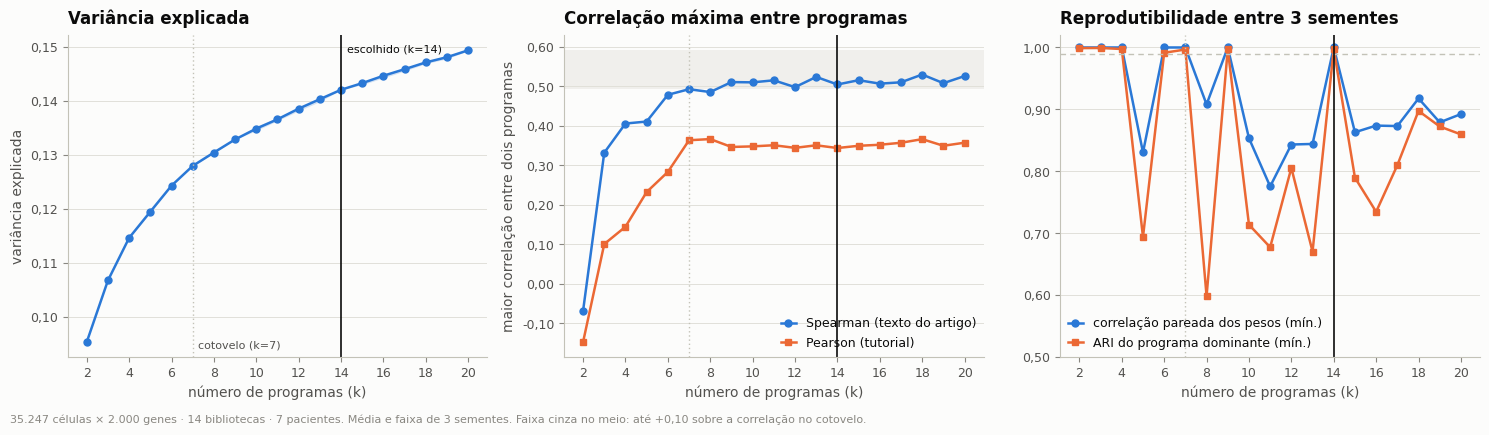

,variância explicada,corr. máx. (Spearman),corr. máx. (Pearson),corr_programas,corr_programas_min,ARI_dominante,ARI_dominante_min
k,,,,,,,
2,0.095,-0.069,-0.148,1.000,1.000,0.999,0.999
3,0.107,0.332,0.101,1.000,1.000,0.999,0.999
4,0.115,0.406,0.145,1.000,1.000,0.998,0.998
5,0.119,0.411,0.233,0.887,0.830,0.796,0.694
6,0.124,0.479,0.283,1.000,1.000,0.994,0.991
7,0.128,0.493,0.364,1.000,1.000,0.998,0.997
8,0.130,0.486,0.367,0.939,0.908,0.732,0.598
9,0.133,0.511,0.347,1.000,1.000,0.998,0.997
10,0.135,0.510,0.348,0.877,0.853,0.790,0.714


In [3]:
sw = nmf.collect_sweep(nmf.CACHE / "varredura")
stab = pd.read_csv(nmf.CACHE / "estabilidade_sementes.csv", index_col=0)
esc = json.loads((nmf.CACHE / "escolha.json").read_text())
K = esc["k_escolhido"]
curvas = sw.groupby("k")[["evar", "maxcorr_spearman", "maxcorr_pearson"]].agg(["mean", "min", "max"])
tab_k = pd.DataFrame({"variância explicada": curvas[("evar", "mean")], "corr. máx. (Spearman)": curvas[("maxcorr_spearman", "mean")],
                      "corr. máx. (Pearson)": curvas[("maxcorr_pearson", "mean")]}).join(stab)
io.save_table(tab_k, NB, "escolha_k", description="NMF por k: variância explicada, correlação máxima e reprodutibilidade")
print(f"cotovelo k = {esc['k_cotovelo']}; candidatos {esc['candidatos']}; reprodutíveis {esc['reprodutiveis']}; "
      f"escolhido k = {K}")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ks = tab_k.index.to_numpy()
ax = axes[0]
ax.fill_between(ks, curvas[("evar", "min")], curvas[("evar", "max")], color=CAT[0], alpha=0.2, lw=0)
ax.plot(ks, tab_k["variância explicada"], "-o", color=CAT[0], ms=5, lw=1.8)
ax.set_ylabel("variância explicada")
ax.set_title("Variância explicada")
ax = axes[1]
ax.plot(ks, tab_k["corr. máx. (Spearman)"], "-o", color=CAT[0], ms=5, lw=1.8, label="Spearman (texto do artigo)")
ax.plot(ks, tab_k["corr. máx. (Pearson)"], "-s", color=CAT[1], ms=5, lw=1.8, label="Pearson (tutorial)")
ax.axhspan(esc["corr_no_cotovelo"], esc["corr_no_cotovelo"] + esc["tolerancia"], color="#f0efec", lw=0, zorder=0)
ax.set_ylabel("maior correlação entre dois programas")
ax.set_title("Correlação máxima entre programas")
ax.legend(loc="lower right")
ax = axes[2]
ax.plot(ks, tab_k["corr_programas_min"], "-o", color=CAT[0], ms=5, lw=1.8, label="correlação pareada dos pesos (mín.)")
ax.plot(ks, tab_k["ARI_dominante_min"], "-s", color=CAT[1], ms=5, lw=1.8, label="ARI do programa dominante (mín.)")
ax.axhline(0.99, color=INK["axis"], lw=1, ls=(0, (4, 3)))
ax.set_ylim(0.5, 1.02)
ax.set_title("Reprodutibilidade entre 3 sementes")
ax.legend(loc="lower left")
for ax in axes:
    ax.axvline(esc["k_cotovelo"], color=INK["axis"], lw=1, ls=(0, (1, 2)))
    ax.axvline(K, color=INK["primary"], lw=1.2)
    ax.set_xlabel("número de programas (k)")
    ax.set_xticks(ks[::2])
    plotting.decimals(ax, "y", 2)
axes[0].annotate(f"cotovelo (k={esc['k_cotovelo']})", (esc["k_cotovelo"], axes[0].get_ylim()[0]), xytext=(4, 6),
                 textcoords="offset points", fontsize=8, color=INK["secondary"])
axes[0].annotate(f"escolhido (k={K})", (K, axes[0].get_ylim()[1]), xytext=(4, -12), textcoords="offset points",
                 fontsize=8, color=INK["primary"])
plotting.note(fig, f"{F.n(N)} células × {F.n(len(genes))} genes · {plotting.N_DESIGN}. Média e faixa de 3 sementes. Faixa cinza "
                   "no meio: até +0,10 sobre a correlação no cotovelo.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "escolha_k", description="Escolha do número de programas da NMF",
                 data=tab_k.reset_index(), data_index=False)
plt.show()
tab_k.round(3)

## 2. Os programas

NMF com k = 14 (semente 0). Cada programa normalizado para o mesmo peso total
(‖W‖ = 1). Os nomes vêm dos genes de maior peso, conferidos contra a
anotação do P09 e o atlas (`anotacao.NMF14_DENOVO`).

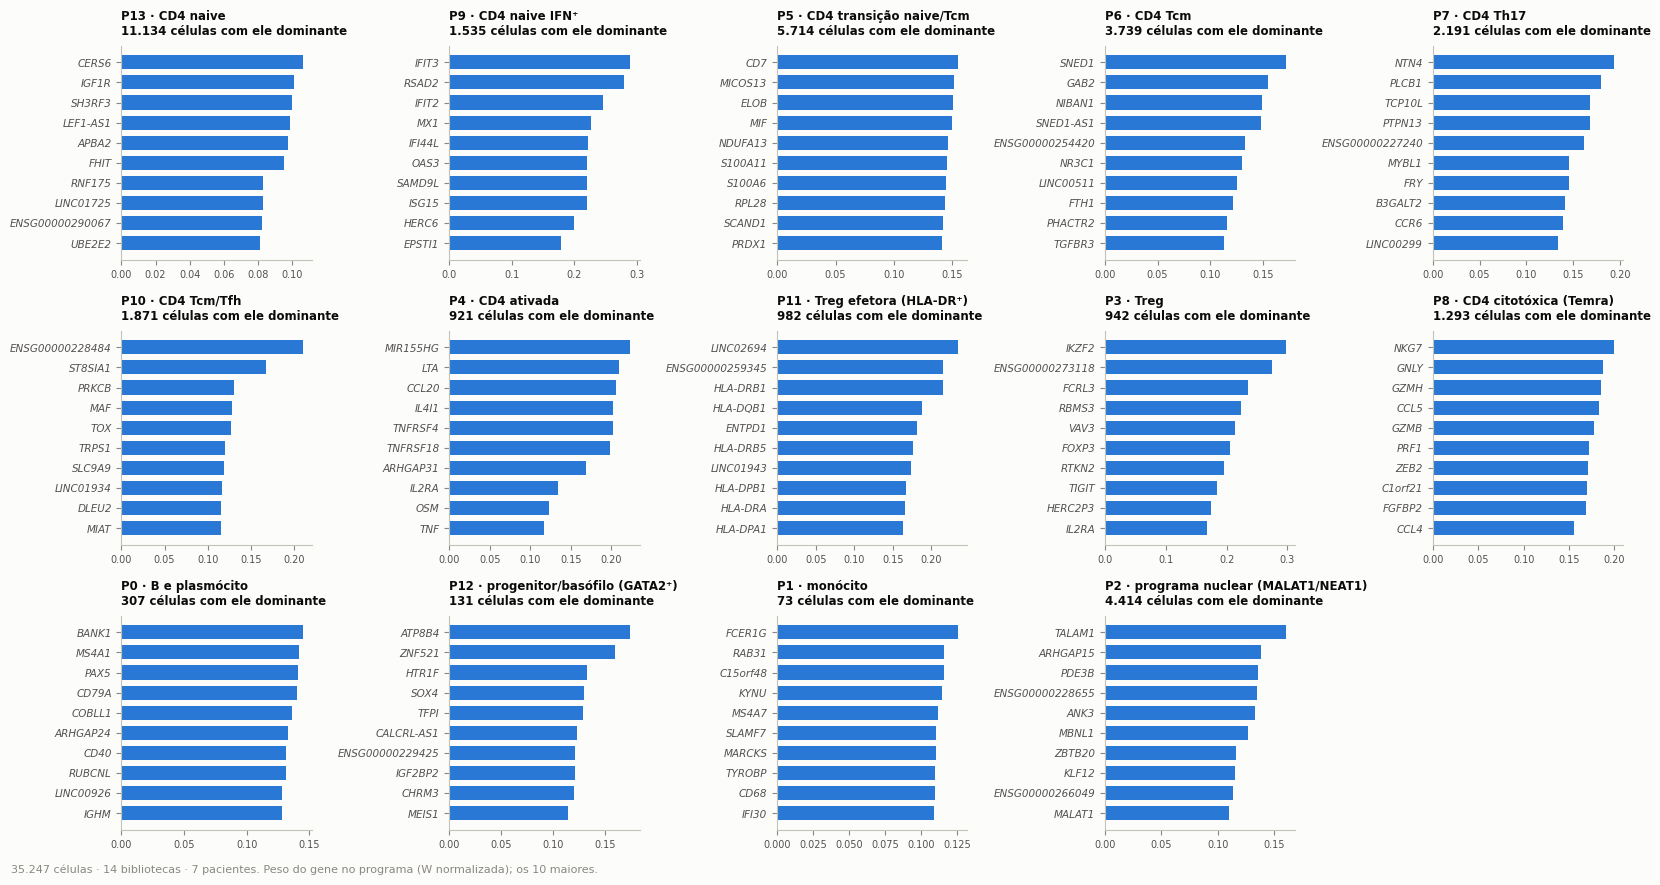

In [4]:
z = np.load(nmf.CACHE / "varredura" / f"nmf_k{K}_s0.npz")
H, W = nmf.normalize(z["H"], z["W"])
dom, share = nmf.dominant(H)
nomes = {k: f"P{k} · {an.NMF14_DENOVO[k][0]}" for k in range(K)}
assert len(an.NMF14_DENOVO) == K
top = nmf.top_genes(W, genes, 30)
top.columns = [nomes[k] for k in range(K)]
io.save_table(top, NB, "genes_por_programa", description="30 genes de maior peso em cada programa", index=False)
ordem = sorted(range(K), key=lambda k: (an.GROUP_ORDER.index(an.NMF14_DENOVO[k][1]), -int((dom == k).sum())))
ncol = 5
nrow = int(np.ceil(K / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.3 * ncol, 2.9 * nrow), squeeze=False)
for i, k in enumerate(ordem):
    ax = axes[i // ncol][i % ncol]
    o = np.argsort(-W[k])[:10][::-1]
    ax.barh(range(10), W[k][o], color=CAT[0], height=0.7)
    ax.set_yticks(range(10))
    ax.set_yticklabels(genes[o], fontsize=7.5, fontstyle="italic")
    ax.set_title(f"{nomes[k]}\n{F.n((dom == k).sum())} células com ele dominante", fontsize=8.5)
    ax.tick_params(axis="x", labelsize=7)
    ax.grid(axis="y", visible=False)
for k in range(K, nrow * ncol):
    axes[k // ncol][k % ncol].axis("off")
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Peso do gene no programa (W normalizada); os 10 maiores.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "genes_por_programa", description="Os 10 genes de maior peso em cada programa",
                 data=top.head(10), data_index=False)
plt.show()

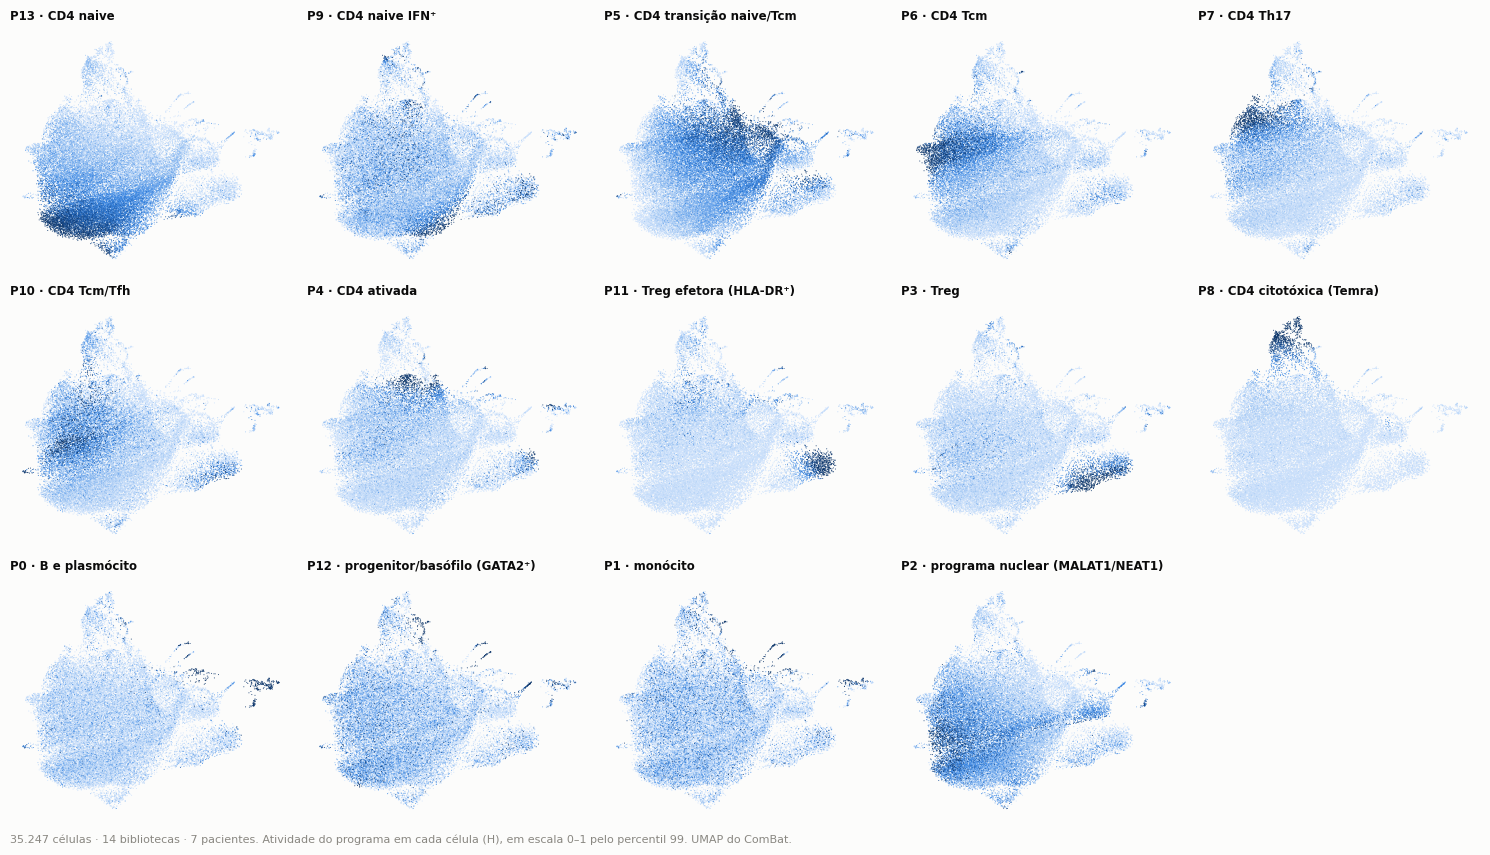

In [5]:
um = integ.obsm["X_umap"]
fig, axes = plt.subplots(nrow, ncol, figsize=(3.0 * ncol, 2.8 * nrow), squeeze=False)
for i, k in enumerate(ordem):
    ax = axes[i // ncol][i % ncol]
    v = H[:, k] / np.quantile(H[:, k], 0.99) if np.quantile(H[:, k], 0.99) > 0 else H[:, k]
    o = np.argsort(v)
    ax.scatter(um[o, 0], um[o, 1], c=np.clip(v[o], 0, 1), s=0.5, lw=0, cmap=plotting.SEQUENTIAL, vmin=0, vmax=1,
               rasterized=True)
    plotting._umap_axes(ax)
    ax.set_title(nomes[k], fontsize=8.5)
for k in range(K, nrow * ncol):
    axes[k // ncol][k % ncol].axis("off")
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Atividade do programa em cada célula (H), em escala 0–1 pelo "
                   "percentil 99. UMAP do ComBat.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "programas_na_umap", description="Atividade de cada programa na UMAP",
                 data=pd.DataFrame({"programa": [nomes[k] for k in range(K)],
                                    "células_dominante": [int((dom == k).sum()) for k in range(K)]}), data_index=False)
plt.show()

## 3. Programa dominante: o "cluster" da NMF

Cada célula vai para o programa de maior contribuição. A fração que esse
programa tem do total mede a mistura: perto de 1, a célula é de um programa
só; perto de 1/k, é uma combinação. É o ponto do artigo: o CD4⁺ é um contínuo.

células cujo programa dominante tem menos de 40% do total: 50,5%; mediana da fração dominante 0,40 (1/k = 0,07)


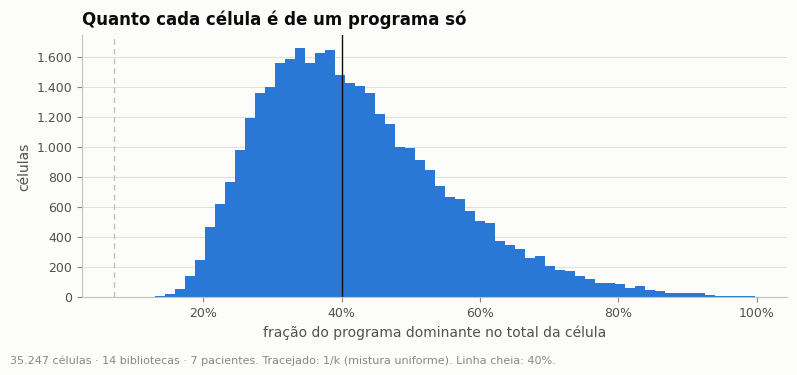

,rótulo,grupo,genes,células,fração dominante (mediana)
programa,,,,,
P13 · CD4 naive,CD4 naive,CD4 naive,"LEF1-AS1, IGF1R, FHIT, TXK, CERS6",11134,0.439
P9 · CD4 naive IFN⁺,CD4 naive IFN⁺,CD4 naive,"IFIT3, RSAD2, MX1, ISG15, OAS3",1535,0.344
P5 · CD4 transição naive/Tcm,CD4 transição naive/Tcm,CD4 memória,"CD7, MIF, S100A11, S100A6, VIM",5714,0.398
P6 · CD4 Tcm,CD4 Tcm,CD4 memória,"NR3C1, TGFBR3, PHACTR2, SAMSN1",3739,0.358
P7 · CD4 Th17,CD4 Th17,CD4 memória,"CCR6, KLRB1, SLC4A10, MYBL1",2191,0.370
P10 · CD4 Tcm/Tfh,CD4 Tcm/Tfh,CD4 memória,"MAF, TOX, PRKCB, ITGA4, IFNG-AS1",1871,0.331
P4 · CD4 ativada,CD4 ativada,CD4 ativada,"MIR155HG, LTA, CCL20, TNFRSF4, IL2RA, TNF",921,0.369
P11 · Treg efetora (HLA-DR⁺),Treg efetora (HLA-DR⁺),Treg,"HLA-DRB1, HLA-DQB1, ENTPD1, FOXP3, LGALS3",982,0.409
P3 · Treg,Treg,Treg,"IKZF2, FOXP3, RTKN2, TIGIT, IL2RA",942,0.395


In [6]:
rot_nmf = np.array([an.NMF14_DENOVO[k][0] for k in dom], dtype=object)
grp_nmf = np.array([an.NMF14_DENOVO[k][1] for k in dom], dtype=object)
tam = pd.DataFrame({"programa": [nomes[k] for k in range(K)], "rótulo": [an.NMF14_DENOVO[k][0] for k in range(K)],
                    "grupo": [an.NMF14_DENOVO[k][1] for k in range(K)], "genes": [an.NMF14_DENOVO[k][2] for k in range(K)],
                    "células": [int((dom == k).sum()) for k in range(K)],
                    "fração dominante (mediana)": [float(np.median(share[dom == k])) if (dom == k).any() else np.nan
                                                   for k in range(K)]}).set_index("programa").loc[[nomes[k] for k in ordem]]
io.save_table(tam, NB, "programas", description="Programas da NMF: rótulo, células com ele dominante, mistura")
mist = float((share < 0.4).mean())
print(f"células cujo programa dominante tem menos de 40% do total: {F.pct(mist, 1)}; mediana da fração dominante "
      f"{F.f(np.median(share), 2)} (1/k = {F.f(1 / K, 2)})")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(share, bins=60, color=CAT[0])
ax.axvline(1 / K, color=INK["axis"], lw=1, ls=(0, (4, 3)))
ax.axvline(0.4, color=INK["primary"], lw=1)
ax.set_xlabel("fração do programa dominante no total da célula")
ax.set_ylabel("células")
plotting.thousands(ax, "y")
plotting.percent(ax, "x")
ax.set_title("Quanto cada célula é de um programa só")
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Tracejado: 1/k (mistura uniforme). Linha cheia: 40%.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "mistura_de_programas", description="Distribuição da fração do programa dominante",
                 data=pd.DataFrame({"fracao_dominante": share}).describe().reset_index(), data_index=False)
plt.show()
tam.round(3)

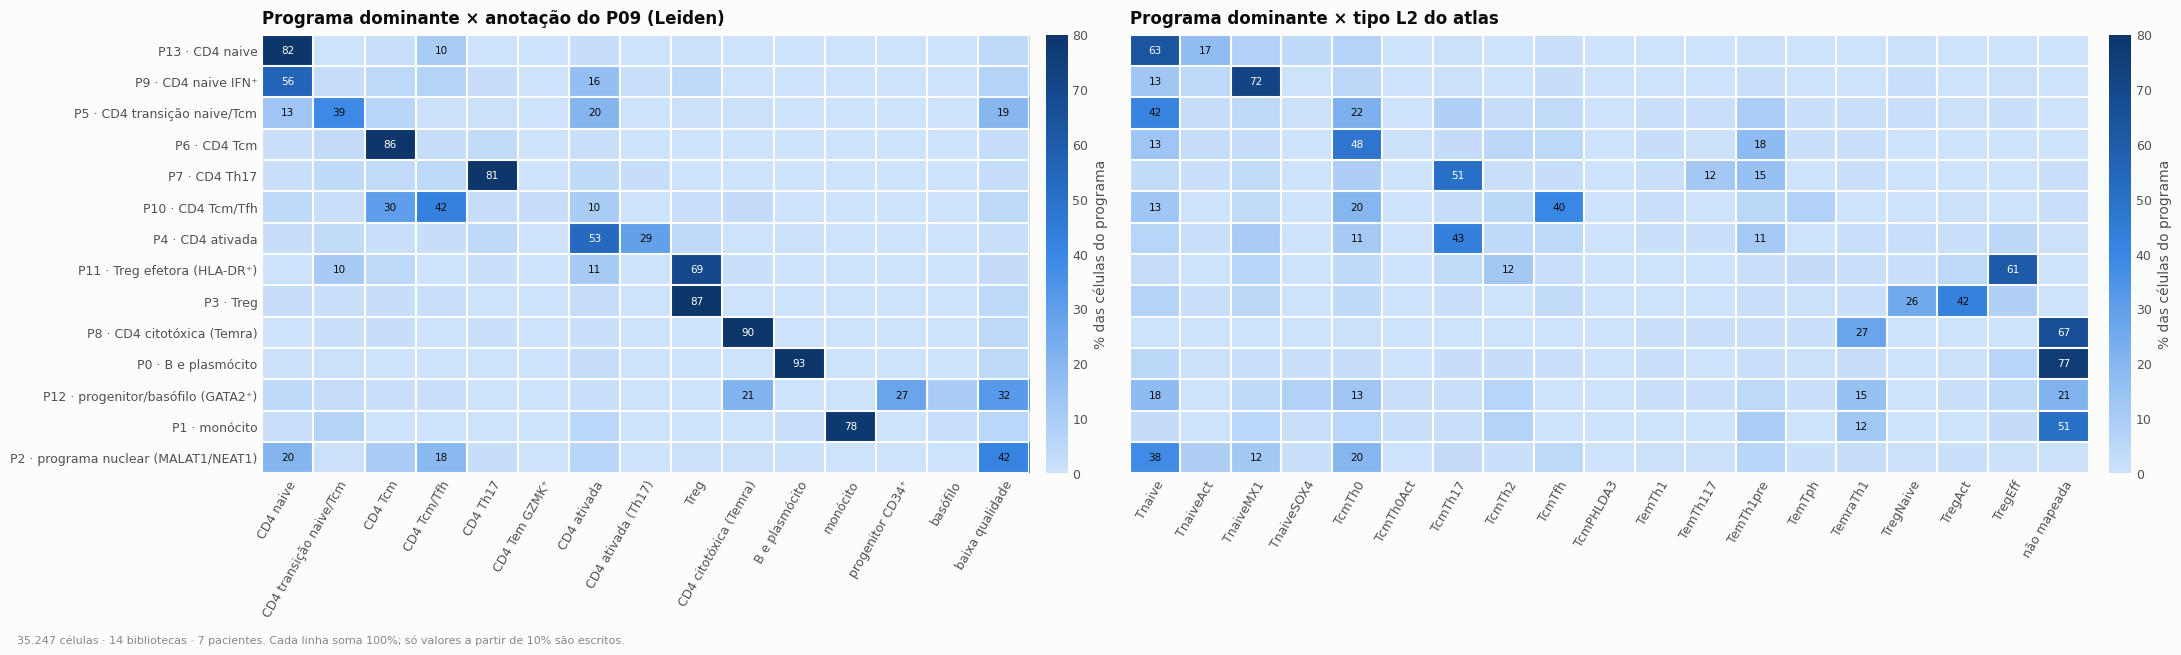

In [7]:
ct = pd.crosstab(pd.Series([nomes[k] for k in dom]), anot["anotacao"].to_numpy(), normalize="index")
ct = ct.reindex(index=[nomes[k] for k in ordem], columns=[l for l in an.LABEL_ORDER if l in ct.columns]).fillna(0)
ct2 = pd.crosstab(pd.Series([nomes[k] for k in dom]), anot["atlas_L2"].fillna("não mapeada").to_numpy(), normalize="index")
ct2 = ct2.reindex(index=[nomes[k] for k in ordem], columns=atlas.L2 + ["não mapeada"]).fillna(0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(22, 6.4), gridspec_kw={"width_ratios": [1, 1.25]})
plotting.heatmap(a1, ct * 100, vmin=0, vmax=80, fmt=".0f", annotate_above=10, cbar_label="% das células do programa",
                 xrotation=60)
a1.set_title("Programa dominante × anotação do P09 (Leiden)")
plotting.heatmap(a2, ct2 * 100, vmin=0, vmax=80, fmt=".0f", annotate_above=10, cbar_label="% das células do programa",
                 xrotation=60)
a2.set_yticklabels([])
a2.set_title("Programa dominante × tipo L2 do atlas")
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Cada linha soma 100%; só valores a partir de 10% são escritos.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "programa_x_anotacao", description="Programa dominante × anotação (P09) e × atlas L2",
                 data=(ct * 100).round(1).rename_axis("programa").reset_index(), data_index=False)
plt.show()

## 4. Os 12 programas publicados (projeção)

A projeção nos programas do atlas (NMFproj) e o controle de qualidade dos
autores: a variância explicada (Evar) e a POH, a fração das 500 HVG da query
que estão em W. Abaixo de 0,1, os autores consideram o ajuste ruim.

genes de W presentes: 1177 de 1271; Evar (todos) 0,306; POH 0,20 (101 de 500 HVG)


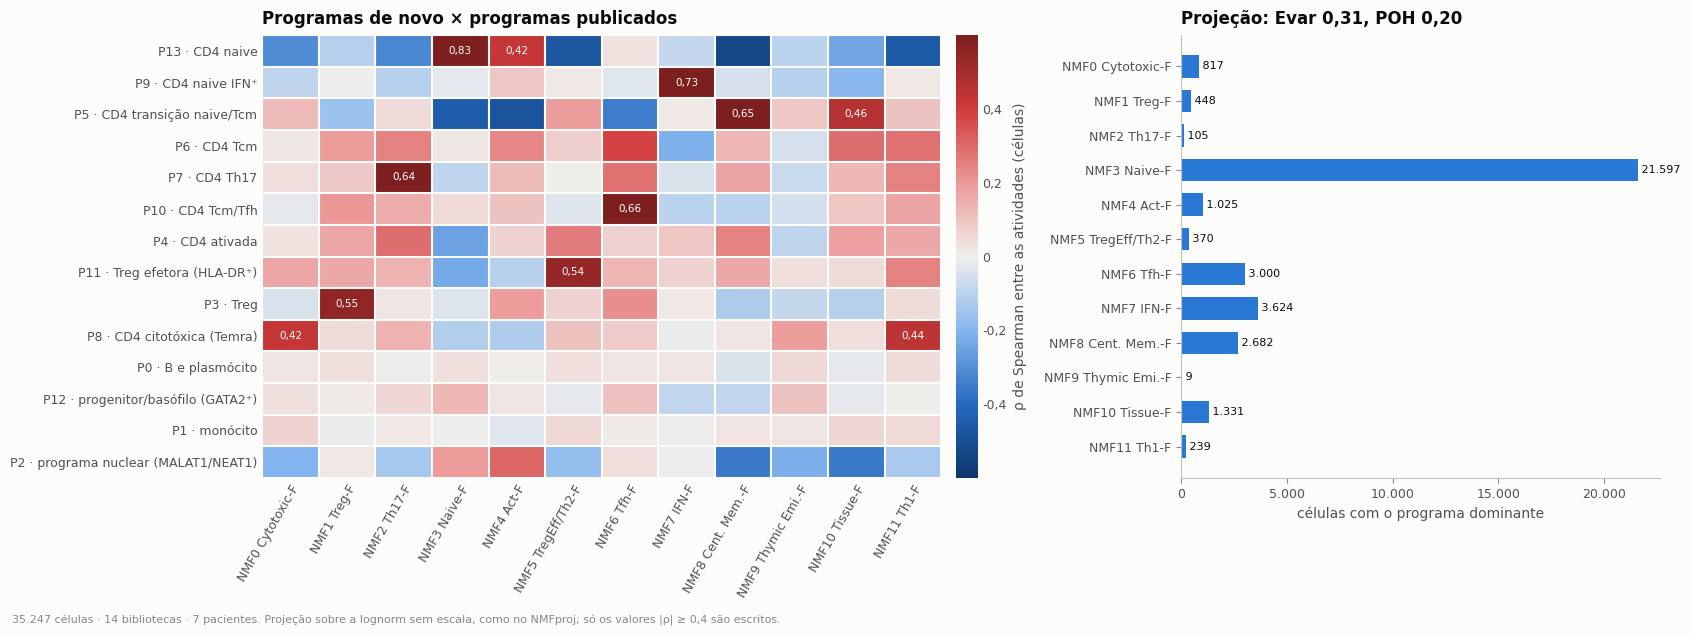

In [8]:
pz = np.load(nmf.CACHE / "projecao.npz", allow_pickle=True)
qc = json.loads((nmf.CACHE / "projecao_qc.json").read_text())
Hp, Wp = nmf.normalize(pz["H"], pz["W"])
progs = [str(p) for p in pz["programas"]]
dp, sp_ = nmf.dominant(Hp)
rot_proj = np.array([an.NMF_PUBLICADOS[progs[i]] for i in dp], dtype=object)
ev = pd.Series(qc["variancia_explicada"])
print(f"genes de W presentes: {qc['genes_presentes']} de {qc['genes_W']}; Evar (todos) {F.f(ev['ALL'], 3)}; "
      f"POH {F.f(qc['poh'], 2)} ({qc['hvg_em_W']} de {qc['hvg_query']} HVG)")
cor = pd.DataFrame(stats.spearmanr(np.column_stack([H, Hp]))[0][:K, K:], index=[nomes[k] for k in range(K)],
                   columns=progs).loc[[nomes[k] for k in ordem]]
dom_proj = pd.Series([progs[i] for i in dp]).value_counts().reindex(progs).fillna(0).astype(int)
io.save_table(cor, NB, "denovo_x_publicados", description="Correlação de Spearman entre programas de novo e publicados")
io.save_table(pd.DataFrame({"Evar": ev.drop("ALL"), "células dominante": dom_proj}), NB, "projecao_qc",
              description="Projeção nos 12 programas publicados: variância explicada e células com cada um dominante")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 6.2), gridspec_kw={"width_ratios": [1.5, 1]})
plotting.heatmap(a1, cor, center=0, vmin=-0.6, vmax=0.6, fmt=".2f", annotate_above=0.4,
                 cbar_label="ρ de Spearman entre as atividades (células)", xrotation=60)
a1.set_title("Programas de novo × programas publicados")
y = np.arange(len(progs))
a2.barh(y, dom_proj.to_numpy(), color=CAT[0], height=0.65)
a2.set_yticks(y)
a2.set_yticklabels(progs)
a2.invert_yaxis()
plotting.thousands(a2, "x")
for yi, v in zip(y, dom_proj.to_numpy()):
    a2.text(v, yi, f" {F.n(v)}", va="center", fontsize=8, color=INK["primary"])
a2.set_xlabel("células com o programa dominante")
a2.grid(axis="y", visible=False)
a2.set_title(f"Projeção: Evar {F.f(ev['ALL'], 2)}, POH {F.f(qc['poh'], 2)}")
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Projeção sobre a lognorm sem escala, como no NMFproj; só os valores "
                   "|ρ| ≥ 0,4 são escritos.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "projecao", description="Programas de novo × publicados e dominância na projeção",
                 data=cor.reset_index(), data_index=False)
plt.show()

## 5. Rótulos gravados

`programas.parquet`, uma linha por célula, com:
* `nmf14_programa`, `nmf14_rotulo`, `nmf14_grupo`, `nmf14_fracao`: programa
  dominante da NMF de novo (k = 14), rótulo, grupo e a fração dominante;
* `nmf9_programa`: programa dominante com k = 9 (sensibilidade);
* `proj_programa`, `proj_rotulo`: programa dominante na projeção nos 12
  publicados;
* `H14_*`, `Hproj_*`: a atividade de cada programa.

In [9]:
z9 = np.load(nmf.CACHE / "varredura" / "nmf_k9_s0.npz")
dom9 = nmf.dominant(nmf.normalize(z9["H"], z9["W"])[0])[0]
out = pd.DataFrame({"cell_key": keys, "library_id": lib, "nmf14_programa": [f"P{k}" for k in dom],
                    "nmf14_rotulo": rot_nmf, "nmf14_grupo": grp_nmf, "nmf14_fracao": share.astype(np.float32),
                    "nmf9_programa": [f"P{k}" for k in dom9], "proj_programa": [progs[i] for i in dp],
                    "proj_rotulo": rot_proj, "proj_fracao": sp_.astype(np.float32)})
for k in range(K):
    out[f"H14_P{k}"] = H[:, k]
for i, p in enumerate(progs):
    out[f"Hproj_{p.split()[0]}"] = Hp[:, i]
io.save_data(out, NB, "programas", description="NMF (Yasumizu et al. 2024): programa dominante (k = 14, k = 9, projeção) e "
                                               "atividades por célula")
print(f"{F.n(len(out))} células; {out['nmf14_programa'].nunique()} programas de novo, "
      f"{out['proj_programa'].nunique()} publicados com alguma célula dominante")

35.247 células; 14 programas de novo, 12 publicados com alguma célula dominante


## Problemas encontrados

In [10]:
log.add("MAJOR", "escolha de k", "os dois critérios do artigo não fixam o número de programas nestes dados",
        evidence=f"cotovelo em k = {esc['k_cotovelo']}; correlação máxima em platô (0,49–0,53) até k = 20; "
                 f"reprodutíveis entre sementes: k = {esc['reprodutiveis']}",
        impact="o k escolhido (14) depende de um desempate, a reprodutibilidade entre sementes, que não está no artigo",
        recommendation="ler os resultados com k = 9 (o outro reprodutível) como sensibilidade (P11)")
log.add("MINOR", "programa nuclear", "um programa (P2) é definido por MALAT1/NEAT1 e concentra células de baixa qualidade",
        evidence=f"{F.n((dom == 2).sum())} células com P2 dominante; {F.pct(ct.loc[nomes[2], 'baixa qualidade'], 0)} "
                 "delas são 'baixa qualidade' no P09",
        impact="a NMF também acha eixos técnicos; o P2 não é um estado celular",
        recommendation="tratar as células com P2 dominante como de baixa qualidade")
log.add("MINOR", "projeção nos programas publicados", "a projeção é dominada pelo programa naive",
        evidence=f"Naive-F dominante em {F.pct((rot_proj == 'CD4 naive').mean(), 0)} das células; Th17-F em "
                 f"{F.n(dom_proj['NMF2 Th17-F'])}; POH {F.f(qc['poh'], 2)} (acima do limite de 0,1 dos autores)",
        impact="os programas publicados são escores contínuos; o dominante é um uso grosseiro deles",
        recommendation="usar a projeção como escore por célula, não como cluster")
log.add("INFO", "o que a NMF separa", "a NMF separa estados que o Leiden 1,0 mistura",
        evidence=f"P9 (resposta a interferon, {F.n((dom == 9).sum())} células, atlas TnaiveMX1) e P11 (Treg efetora HLA-DR⁺ "
                 f"CD39⁺, {F.n((dom == 11).sum())} células, atlas TregEff)",
        impact="esses estados ficam visíveis sem subir a resolução do Leiden",
        recommendation="nenhuma")
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    0
MAJOR       1
MINOR       2
INFO        1


severity,location,problem,evidence,impact,recommendation
MAJOR,escolha de k,os dois critérios do artigo não fixam o número de programas nestes dados,"cotovelo em k = 7; correlação máxima em platô (0,49–0,53) até k = 20; reprodutíveis entre sementes: k = [9, 14]","o k escolhido (14) depende de um desempate, a reprodutibilidade entre sementes, que não está no artigo",ler os resultados com k = 9 (o outro reprodutível) como sensibilidade (P11)
MINOR,programa nuclear,um programa (P2) é definido por MALAT1/NEAT1 e concentra células de baixa qualidade,4.414 células com P2 dominante; 42% delas são 'baixa qualidade' no P09,a NMF também acha eixos técnicos; o P2 não é um estado celular,tratar as células com P2 dominante como de baixa qualidade
MINOR,projeção nos programas publicados,a projeção é dominada pelo programa naive,"Naive-F dominante em 61% das células; Th17-F em 105; POH 0,20 (acima do limite de 0,1 dos autores)",os programas publicados são escores contínuos; o dominante é um uso grosseiro deles,"usar a projeção como escore por célula, não como cluster"
INFO,o que a NMF separa,"a NMF separa estados que o Leiden 1,0 mistura","P9 (resposta a interferon, 1.535 células, atlas TnaiveMX1) e P11 (Treg efetora HLA-DR⁺ CD39⁺, 982 células, atlas TregEff)",esses estados ficam visíveis sem subir a resolução do Leiden,nenhuma


## Conclusão

**O número de programas.** Os dois critérios do artigo só limitam por baixo
(k > 7): a correlação máxima entre componentes não sobe depois do cotovelo.
O desempate pela reprodutibilidade entre sementes deu k = 14. O k = 9 é a
outra opção reprodutível e entra no P11 como sensibilidade.

**Os 14 programas têm leitura biológica:** naive, transição, Tcm (Th0),
Tfh-like (MAF, TOX), Th17 (CCR6, KLRB1), ativação pelo TCR (MIR155HG, LTA,
TNFRSF4), Treg, Treg efetora (HLA de classe II, CD39), citotóxico, resposta a
interferon e os contaminantes (B, monócito, progenitor/basófilo). Um programa
(MALAT1/NEAT1) é técnico. Dois estados que o Leiden 1,0 misturava aparecem
sozinhos: a resposta a interferon (TnaiveMX1 no atlas) e a Treg efetora
(TregEff).

**O contínuo.** Em metade das células (50,5%), o programa dominante tem menos
de 40% do total: a célula é uma combinação de programas, como o artigo
defende para o CD4⁺. O "cluster" da NMF (programa dominante) é, portanto, uma
simplificação. Para as perguntas biológicas, a atividade de cada programa por
célula (H) é a informação útil.

**Os 12 programas publicados** projetam bem nos nossos dados (POH 0,20, acima
do limite de 0,1; Evar 0,31). O dominante, porém, é quase sempre o Naive-F
(61%): servem como escores contínuos, não como clusters.